# Упражнение 5.1: вейвлет-преобразование Хаара

Задача: считать изображение, перевести в градации серого, выполнить `dwt2` с вейвлетом Haar, построить гистограмму `cA` и сопоставить изображения с наборами `cA`, `cH`, `cV`, `cD`.

In [1]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import pywt
import matplotlib.pyplot as plt

IMAGE_PATH = Path('input_images/st-petersburg-3714288_1280.jpg')
CANDIDATE_DIR = Path('candidate_images')
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

if not IMAGE_PATH.exists():
    raise FileNotFoundError(f'Не найден файл: {IMAGE_PATH}')
if not CANDIDATE_DIR.exists():
    raise FileNotFoundError(f'Не найдена папка: {CANDIDATE_DIR}')

## 1. Чтение и перевод в grayscale

In [2]:
image_bgr = cv2.imread(str(IMAGE_PATH), cv2.IMREAD_COLOR)
if image_bgr is None:
    raise ValueError('OpenCV не смог считать изображение')

gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
print(f'Размер grayscale: {gray.shape[1]}x{gray.shape[0]}')
print(f'Диапазон: {gray.min()}..{gray.max()}')

Размер grayscale: 1280x853
Диапазон: 0..255


## 2. Haar DWT

In [3]:
cA, (cH, cV, cD) = pywt.dwt2(gray, 'haar')
coefficients = {'cA': cA, 'cH': cH, 'cV': cV, 'cD': cD}

for name, coef in coefficients.items():
    print(
        f'{name}: shape={coef.shape}, '
        f'min={coef.min():.1f}, max={coef.max():.1f}, '
        f'mean={coef.mean():.3f}, std={coef.std():.3f}'
    )

cA: shape=(427, 640), min=0.5, max=505.0, mean=225.360, std=105.745
cH: shape=(427, 640), min=-236.5, max=239.0, mean=-0.198, std=35.919
cV: shape=(427, 640), min=-240.0, max=211.0, mean=-0.043, std=25.653
cD: shape=(427, 640), min=-159.0, max=163.5, mean=-0.023, std=17.543


## 3. Гистограмма cA

Для ответа используется гистограмма `cA` на 256 бинов: `np.histogram(cA.ravel(), bins=256)`.

Максимальное значение h(n): 1950
Индекс максимального бина: 73
Границы бина: 144.361..146.332


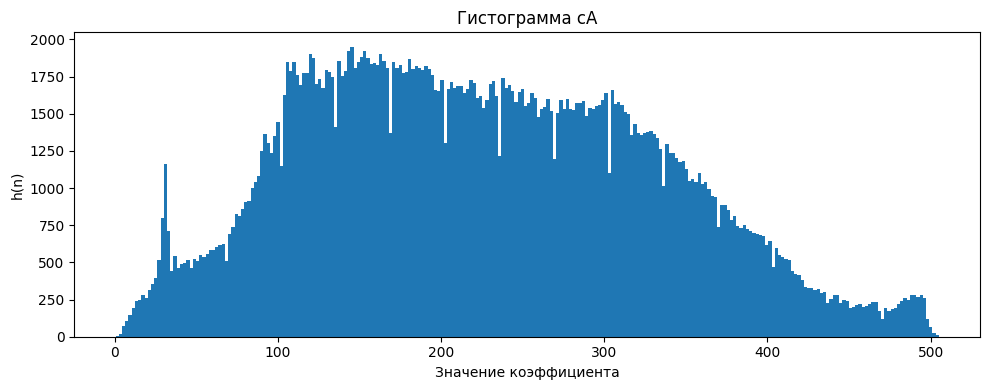

In [4]:
hist, bin_edges = np.histogram(cA.ravel(), bins=256)
max_h = int(hist.max())
max_bin = int(hist.argmax())

print(f'Максимальное значение h(n): {max_h}')
print(f'Индекс максимального бина: {max_bin}')
print(f'Границы бина: {bin_edges[max_bin]:.3f}..{bin_edges[max_bin + 1]:.3f}')

plt.figure(figsize=(10, 4))
plt.hist(cA.ravel(), bins=256)
plt.title('Гистограмма cA')
plt.xlabel('Значение коэффициента')
plt.ylabel('h(n)')
plt.tight_layout()
plt.show()

## 4. Сопоставление изображений с фильтрами

Изображения в задании сохранены как коэффициенты, обрезанные в диапазон `0..255`: `np.clip(coef, 0, 255).astype(uint8)`. Из-за JPEG-сжатия сравниваем по средней абсолютной ошибке.

In [5]:
def coefficient_to_image(coef):
    return np.clip(coef, 0, 255).astype(np.uint8)

rows = []
for path in sorted(CANDIDATE_DIR.glob('c_*_st-petersburg-3714288_1280.jpg')):
    image_id = path.name.split('_')[1]
    candidate = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if candidate is None:
        raise ValueError(f'Не удалось прочитать {path}')

    for name, coef in coefficients.items():
        expected = coefficient_to_image(coef)
        diff = expected.astype(np.int16) - candidate.astype(np.int16)
        rows.append({
            'image_id': image_id,
            'filter': name,
            'mae': float(np.mean(np.abs(diff))),
            'mse': float(np.mean(diff.astype(np.float32) ** 2)),
        })

comparison = pd.DataFrame(rows).sort_values(['image_id', 'mae']).reset_index(drop=True)
display(comparison)

answers = comparison.loc[comparison.groupby('image_id')['mae'].idxmin()]
answers = answers.sort_values('image_id')[['image_id', 'filter', 'mae']]
display(answers)

,image_id,filter,mae,mse
0,167,cV,0.972318,2.460440
1,167,cD,9.339202,366.434235
2,167,cH,14.050307,771.193787
3,167,cA,186.458724,39421.917969
4,471,cA,1.124228,2.883266
5,471,cH,183.275962,38606.406250
6,471,cV,187.040201,39599.429688
7,471,cD,188.811732,40300.664062
8,807,cD,0.938923,2.360945
9,807,cV,9.291156,361.926514


,image_id,filter,mae
0,167,cV,0.972318
4,471,cA,1.124228
8,807,cD,0.938923
12,863,cH,1.008918


## Ответы для формы

- Максимальное значение `h(n)`: `1950`
- `c_167`: `cV`
- `c_471`: `cA`
- `c_807`: `cD`
- `c_863`: `cH`